In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import sys
import yaml
from pathlib import Path
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from scipy.spatial.distance import hamming

# make figures paper quality
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

import warnings
warnings.filterwarnings("ignore")

/home/peidli/miniconda3/envs/sc_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)

seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/'

In [3]:
cell_line_dict={
    '01': 'H1975',
    '02': 'H1299',
    '03': 'A549'
}

In [58]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
# df = pd.read_csv('/Users/peidli/work/data/SYMPHONY/pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

In [64]:
# where did this sample go: sym_03_03_TP3_S45
'sym-03-03-TP3' in df.columns, 'sym-03-03-TP2' in df.columns

(False, True)

In [86]:
6*(3*3) + 3

57

In [71]:
sample_names = list(pd.read_csv('../resources/pooled_screen_1_fastqs.txt', sep='\t', index_col=0).index)
sample_names = [x for x in sample_names if 'Undetermined_S0' not in x]
s = [x.split('_S')[0] for x in sample_names]

In [72]:
'sym-03-03-TP3' in s, 'sym-03-03-TP2' in s

(False, True)

In [75]:
sa = """Sym-pool-1-1_S55_L001
sym-01-02-TP6_S17_L001
sym-02-02-TP3_S26_L001
sym-03-01-TP6_S52_L001
Sym-pool-1-1_S55_L002
sym-01-02-TP6_S17_L002
sym-02-02-TP3_S26_L002
sym-03-01-TP6_S52_L002
Sym-pool-1-2_S56_L001
sym-01-03-TP1_S3_L001
sym-02-02-TP4_S29_L001
sym-03-02-TP1_S38_L001
Sym-pool-1-2_S56_L002
sym-01-03-TP1_S3_L002
sym-02-02-TP4_S29_L002
sym-03-02-TP1_S38_L002
Sym-pool-1-3_S57_L001
sym-01-03-TP2_S6_L001
sym-02-02-TP5_S32_L001
sym-03-02-TP2_S41_L001
Sym-pool-1-3_S57_L002
sym-01-03-TP2_S6_L002
sym-02-02-TP5_S32_L002
sym-03-02-TP2_S41_L002
Undetermined_S0_L001
sym-01-03-TP3_S9_L001
sym-02-02-TP6_S35_L001
sym-03-02-TP3_S44_L001
Undetermined_S0_L002
sym-01-03-TP3_S9_L002
sym-02-02-TP6_S35_L002
sym-03-02-TP3_S44_L002
sym-01-01-TP1_S1_L001
sym-01-03-TP4_S12_L001
sym-02-03-TP1_S21_L001
sym-03-02-TP4_S47_L001
sym-01-01-TP1_S1_L002
sym-01-03-TP4_S12_L002
sym-02-03-TP1_S21_L002
sym-03-02-TP4_S47_L002
sym-01-01-TP2_S4_L001
sym-01-03-TP5_S15_L001
sym-02-03-TP2_S24_L001
sym-03-02-TP5_S50_L001
sym-01-01-TP2_S4_L002
sym-01-03-TP5_S15_L002
sym-02-03-TP2_S24_L002
sym-03-02-TP5_S50_L002
sym-01-01-TP3_S7_L001
sym-01-03-TP6_S18_L001
sym-02-03-TP3_S27_L001
sym-03-02-TP6_S53_L001
sym-01-01-TP3_S7_L002
sym-01-03-TP6_S18_L002
sym-02-03-TP3_S27_L002
sym-03-02-TP6_S53_L002
sym-01-01-TP4_S10_L001
sym-02-01-TP1_S19_L001
sym-02-03-TP4_S30_L001
sym-03-03-TP1_S39_L001
sym-01-01-TP4_S10_L002
sym-02-01-TP1_S19_L002
sym-02-03-TP4_S30_L002
sym-03-03-TP1_S39_L002
sym-01-01-TP5_S13_L001
sym-02-01-TP2_S22_L001
sym-02-03-TP5_S33_L001
sym-03-03-TP2_S42_L001
sym-01-01-TP5_S13_L002
sym-02-01-TP2_S22_L002
sym-02-03-TP5_S33_L002
sym-03-03-TP2_S42_L002
sym-01-01-TP6_S16_L001
sym-02-01-TP3_S25_L001
sym-02-03-TP6_S36_L001
sym-03-03-TP3_S45_L001
sym-01-01-TP6_S16_L002
sym-02-01-TP3_S25_L002
sym-02-03-TP6_S36_L002
sym-03-03-TP3_S45_L002
sym-01-02-TP1_S2_L001
sym-02-01-TP4_S28_L001
sym-03-01-TP1_S37_L001
sym-03-03-TP4_S48_L001
sym-01-02-TP1_S2_L002
sym-02-01-TP4_S28_L002
sym-03-01-TP1_S37_L002
sym-03-03-TP4_S48_L002
sym-01-02-TP2_S5_L001
sym-02-01-TP5_S31_L001
sym-03-01-TP2_S40_L001
sym-03-03-TP5_S51_L001
sym-01-02-TP2_S5_L002
sym-02-01-TP5_S31_L002
sym-03-01-TP2_S40_L002
sym-03-03-TP5_S51_L002
sym-01-02-TP3_S8_L001
sym-02-01-TP6_S34_L001
sym-03-01-TP3_S43_L001
sym-03-03-TP6_S54_L001
sym-01-02-TP3_S8_L002
sym-02-01-TP6_S34_L002
sym-03-01-TP3_S43_L002
sym-03-03-TP6_S54_L002
sym-01-02-TP4_S11_L001
sym-02-02-TP1_S20_L001
sym-03-01-TP4_S46_L001
sym-01-02-TP4_S11_L002
sym-02-02-TP1_S20_L002
sym-03-01-TP4_S46_L002
sym-01-02-TP5_S14_L001
sym-02-02-TP2_S23_L001
sym-03-01-TP5_S49_L001""".split('\n')
sa = [x.split('_L00')[0] for x in sa]

In [84]:
Ss = [int(x.split('_S')[-1]) for x in sample_names]
np.sort(Ss) # S45 is missing

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 46, 47, 48, 49, 50, 51, 52,
       53, 54, 55, 56, 57])

In [5]:
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

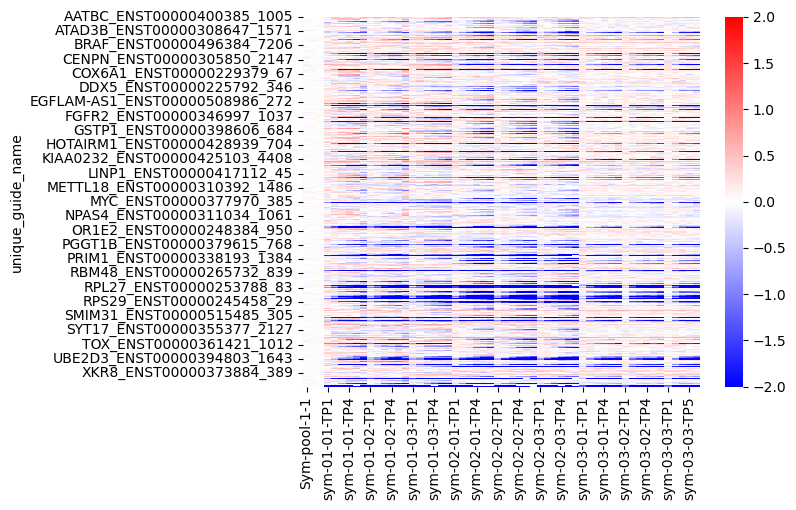

In [6]:
sns.heatmap(l2fc, cmap='bwr', center=0, vmin=-2, vmax=2); 

In [50]:
l2fc

,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,...,sym-03-02-TP2,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,-0.055718,0.058491,-0.005046,0.146379,0.093119,0.171926,0.146826,0.263347,-0.311939,0.207365,...,0.136882,0.151695,0.165305,0.299281,0.115117,0.180513,0.155582,0.234000,0.186007,0.145290
AATBC_ENST00000400385_1562,-0.037604,0.053324,-0.017307,0.162327,0.304365,0.203560,0.178061,0.159180,-0.222893,0.096761,...,0.268925,0.145530,0.175197,0.206139,0.270807,0.188596,0.129100,0.061218,0.252867,0.307523
AATBC_ENST00000400385_1938,0.003343,-0.020331,0.016744,0.238476,0.313541,0.299696,0.299845,0.098093,0.214944,0.192703,...,0.296400,0.152115,0.311084,0.262134,0.296892,0.304033,0.203057,0.277391,0.223215,0.347488
AATBC_ENST00000400385_2713,0.003771,0.010187,-0.014068,-0.056858,-0.109314,-0.208933,-0.293480,-0.352484,0.054507,-0.033895,...,-0.188863,0.107675,0.005479,-0.026093,-0.124534,0.065793,-0.083095,-0.007920,-0.124404,0.073316
AATBC_ENST00000400385_28,0.068932,-0.089146,0.015756,-0.094619,0.211245,0.055164,0.137978,0.101414,0.124156,0.055624,...,0.066973,0.129426,0.131015,0.050470,0.150220,0.213198,0.158464,0.153799,0.121947,0.182871
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RPS16_ENST00000251453_280,0.024012,-0.018602,-0.005742,-0.629586,-2.810907,-4.717307,-6.377048,NaN,NaN,-1.582571,...,-1.502505,-2.153658,-2.374335,-2.447041,-3.168989,-0.343460,-1.473122,-2.924561,-3.004127,-3.186824
RPS16_ENST00000251453_300,0.010077,0.034943,-0.046214,0.489401,-0.189671,-0.844518,-1.326083,-1.722927,-2.506502,-0.276062,...,-2.034478,-2.573987,-3.056848,-2.863560,-3.287096,-0.325108,-1.596693,-3.612750,-3.400717,-3.485071
RPS5_ENST00000196551_431,-0.024501,0.033819,-0.009958,0.031648,-0.482441,-0.938698,-1.211750,-1.526984,-2.067376,-0.324286,...,-0.621449,-0.805987,-1.154413,-0.988961,-1.248182,-0.000952,-0.600880,-1.396469,-1.410026,-1.565024


In [7]:
tab = l2fc.iloc[:, 3:].T
tab['time'] = [x.split('-')[-1] for x in tab.index]
tab['replicate'] = [x.split('-')[2] for x in tab.index]
tab['cell_line'] = [x.split('-')[1] for x in tab.index]

In [8]:
tab.head()

unique_guide_name,AATBC_ENST00000400385_1005,AATBC_ENST00000400385_1562,AATBC_ENST00000400385_1938,AATBC_ENST00000400385_2713,AATBC_ENST00000400385_28,AATBC_ENST00000400385_3041,AATBC_ENST00000400385_3400,AATBC_ENST00000400385_3822,AATBC_ENST00000400385_4379,AATBC_ENST00000400385_827,...,RPL27_ENST00000253788_118,RPL8_ENST00000262584_578,RPS16_ENST00000251453_280,RPS16_ENST00000251453_300,RPS5_ENST00000196551_431,RPS5_ENST00000196551_574,RPS5_ENST00000196551_68,time,replicate,cell_line
sym-01-01-TP1,0.146379,0.162327,0.238476,-0.056858,-0.094619,0.166895,0.379741,-0.244099,0.090764,0.206983,...,-0.386298,-0.311834,-0.629586,0.489401,0.031648,0.192609,-3.695682,TP1,01,01
sym-01-01-TP2,0.093119,0.304365,0.313541,-0.109314,0.211245,0.160984,0.304452,-0.332957,0.061509,0.469867,...,-0.779351,-1.882949,-2.810907,-0.189671,-0.482441,-0.141250,-3.943488,TP2,01,01
sym-01-01-TP3,0.171926,0.203560,0.299696,-0.208933,0.055164,0.237148,0.196760,-0.178280,0.246682,0.324229,...,-1.286403,-3.043401,-4.717307,-0.844518,-0.938698,-0.277374,-4.567845,TP3,01,01
sym-01-01-TP4,0.146826,0.178061,0.299845,-0.293480,0.137978,0.223238,0.018388,-0.125732,0.282914,0.308189,...,-1.575088,-3.179438,-6.377048,-1.326083,-1.211750,-0.596586,-4.924299,TP4,01,01
sym-01-01-TP5,0.263347,0.159180,0.098093,-0.352484,0.101414,0.163022,0.093016,0.001457,0.109052,0.213504,...,-2.171090,-2.906995,NaN,-1.722927,-1.526984,-0.612908,-4.651405,TP5,01,01


In [9]:
mtab = tab.fillna(0).drop('replicate', axis=1).groupby(['cell_line', 'time']).mean()  # mean over replicates

In [10]:
# normalize to max value of each cell line
mtab_ = mtab.reset_index(level=1, drop=True).reset_index()
mtab_ = mtab_.groupby('cell_line').max()
nmtab = mtab / mtab_

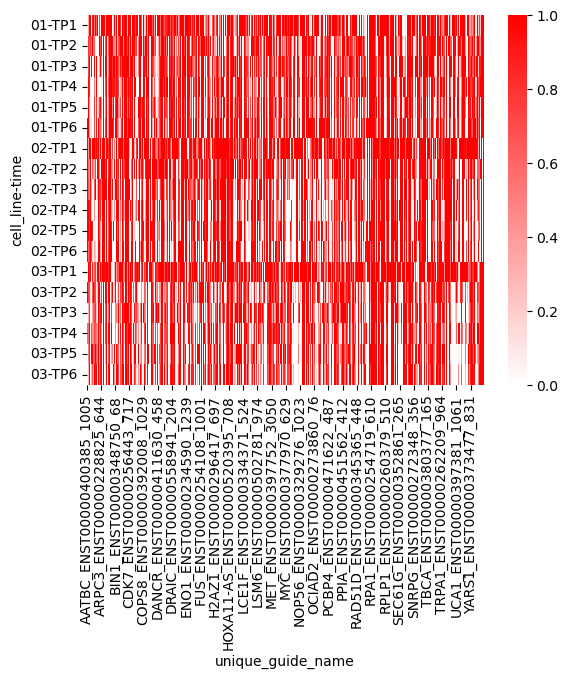

In [11]:
sns.heatmap(nmtab, cmap='bwr', center=0, vmin=0, vmax=1);

In [17]:
data = nmtab.replace([np.inf, -np.inf], np.nan).fillna(0).T

In [12]:
# cluster the guides
from scipy.cluster.hierarchy import dendrogram, linkage, cut_tree
Z = linkage(, 'ward')

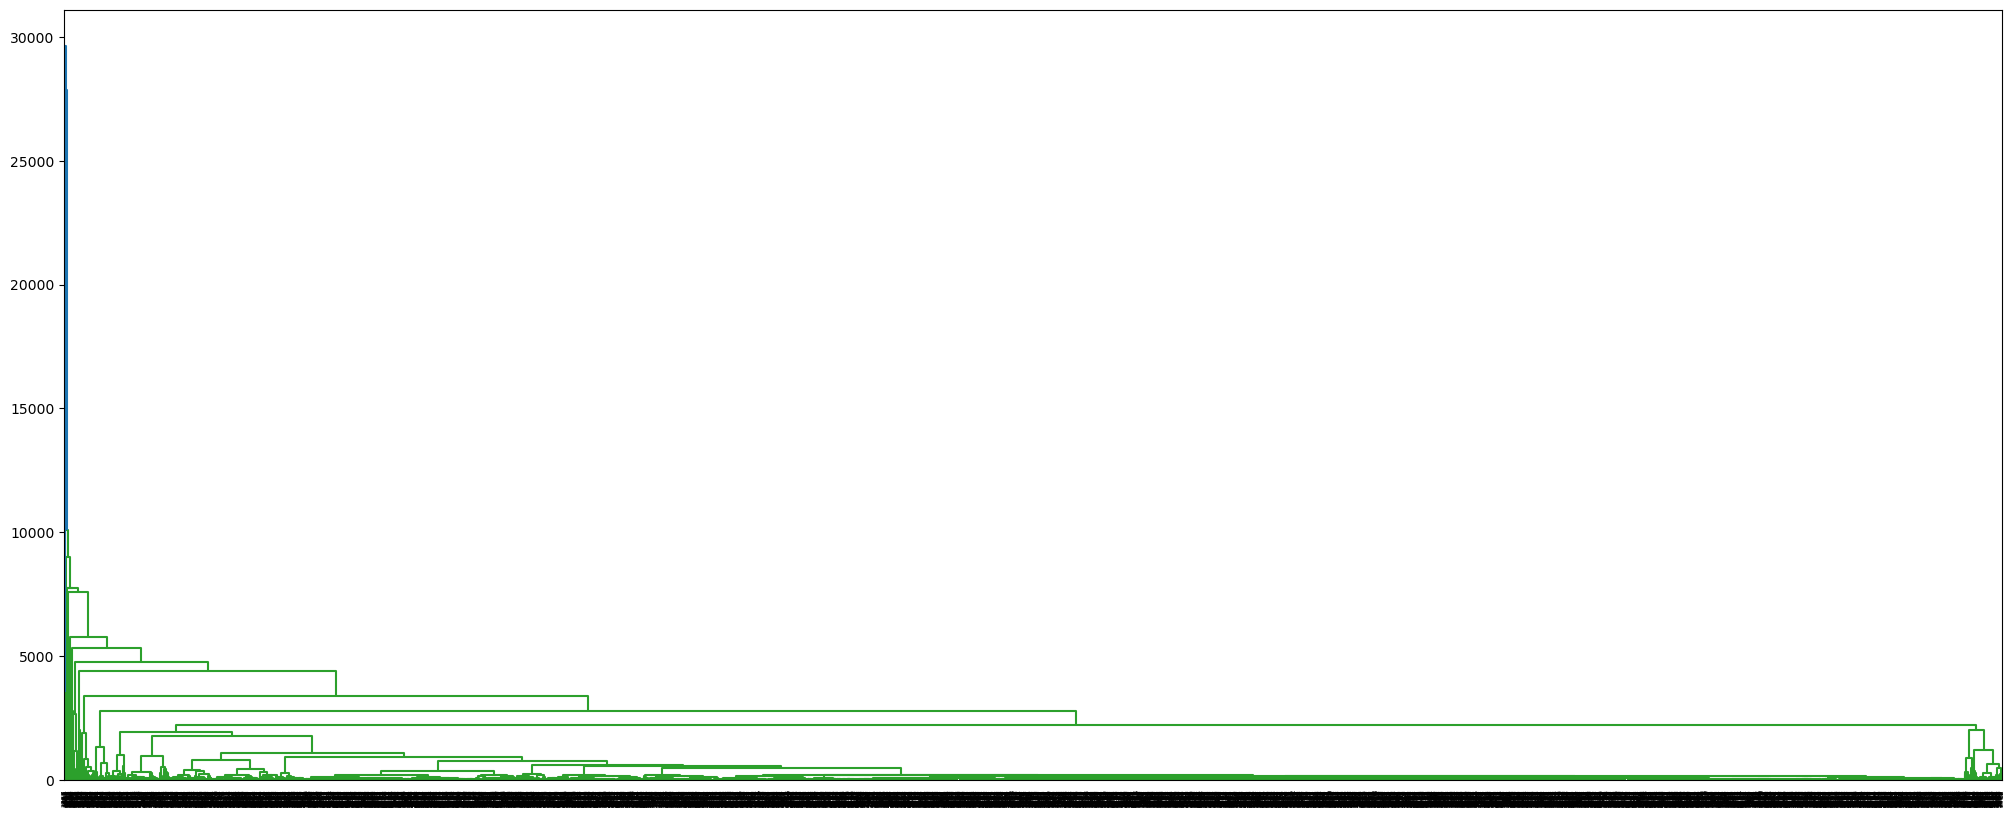

In [13]:
fig = pl.figure(figsize=(25, 10))
dn = dendrogram(Z)

In [14]:
cut_tree(Z, height=)

array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [0]])

In [15]:
np.unique(cut_tree(Z, n_clusters=2), return_counts=True)

(array([0, 1]), array([6224,    1]))

In [37]:
data = l2fc.replace([np.inf, -np.inf], np.nan).fillna(0).iloc[:, 3:]

In [38]:
from sklearn.cluster import KMeans
# from sklearn.preprocessing import MaxAbsScaler

# prep = MaxAbsScaler()
kmeans = KMeans(n_clusters=4, random_state=0)

# scaled_data = prep.fit_transform(wide_df)
kmeans.fit(data)


KMeans(n_clusters=4, random_state=0)

In [39]:
from sklearn.metrics import silhouette_score
print(silhouette_score(data, kmeans.labels_))

0.5889491998663221


In [40]:
np.unique(kmeans.labels_, return_counts=True)

(array([0, 1, 2, 3], dtype=int32), array([ 220, 4910,  361,  734]))

In [41]:
data

,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,sym-01-02-TP2,sym-01-02-TP3,sym-01-02-TP4,...,sym-03-02-TP2,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,0.146379,0.093119,0.171926,0.146826,0.263347,-0.311939,0.207365,-0.017887,-0.056298,-0.188685,...,0.136882,0.151695,0.165305,0.299281,0.115117,0.180513,0.155582,0.234000,0.186007,0.145290
AATBC_ENST00000400385_1562,0.162327,0.304365,0.203560,0.178061,0.159180,-0.222893,0.096761,-0.040418,-0.207962,-0.117123,...,0.268925,0.145530,0.175197,0.206139,0.270807,0.188596,0.129100,0.061218,0.252867,0.307523
AATBC_ENST00000400385_1938,0.238476,0.313541,0.299696,0.299845,0.098093,0.214944,0.192703,0.348865,0.222431,0.253394,...,0.296400,0.152115,0.311084,0.262134,0.296892,0.304033,0.203057,0.277391,0.223215,0.347488
AATBC_ENST00000400385_2713,-0.056858,-0.109314,-0.208933,-0.293480,-0.352484,0.054507,-0.033895,-0.177839,-0.115870,-0.035753,...,-0.188863,0.107675,0.005479,-0.026093,-0.124534,0.065793,-0.083095,-0.007920,-0.124404,0.073316
AATBC_ENST00000400385_28,-0.094619,0.211245,0.055164,0.137978,0.101414,0.124156,0.055624,0.085335,0.164197,0.162918,...,0.066973,0.129426,0.131015,0.050470,0.150220,0.213198,0.158464,0.153799,0.121947,0.182871
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RPS16_ENST00000251453_280,-0.629586,-2.810907,-4.717307,-6.377048,0.000000,0.000000,-1.582571,-3.643995,-5.605609,-7.161596,...,-1.502505,-2.153658,-2.374335,-2.447041,-3.168989,-0.343460,-1.473122,-2.924561,-3.004127,-3.186824
RPS16_ENST00000251453_300,0.489401,-0.189671,-0.844518,-1.326083,-1.722927,-2.506502,-0.276062,-0.616355,-1.549096,-1.886128,...,-2.034478,-2.573987,-3.056848,-2.863560,-3.287096,-0.325108,-1.596693,-3.612750,-3.400717,-3.485071
RPS5_ENST00000196551_431,0.031648,-0.482441,-0.938698,-1.211750,-1.526984,-2.067376,-0.324286,-0.789110,-1.346980,-1.435623,...,-0.621449,-0.805987,-1.154413,-0.988961,-1.248182,-0.000952,-0.600880,-1.396469,-1.410026,-1.565024


In [ ]:
pl.plot(data.iloc[0])

In [45]:
len([1,2,3,4,5,6] * 8)

54

In [56]:
t = [1,2,3,4,5,6] * 8 + [1,2,4,5,6]